In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Part A : Setup + Baseline

## 1. Load the dataset and define:
 - X = feature matrix (numeric features only; encode categories if needed)
 - y = target

In [2]:
data = pd.read_csv("data/processed/Airbnb_Open_Data_Cleaned.csv", low_memory=False)

display(data)
# cleaning the dataset, dropping null an unnecessary values

data = data.drop([
                    "id",
                    "host_id",
                    "license",
                    "country",
                    "country_code",
                    "house_rules",
                    "name",
                    "host_name",
                    "neighbourhood",
                    "neighbourhood_group",
                    "last_review",
                    "service_fee"
                    ],
                axis=1
                )

(data["minimum_nights"] > 365).sum()
#only 17 values, so i clear the outliers

valid_min_nights = data["minimum_nights"].between(0,365)
valid_avail_365 = data["availability_365"].between(0,365)

data.loc[~valid_min_nights, "minimum_nights"] = np.nan
data.loc[~valid_avail_365, "availability_365"] = np.nan


#drop rows only when the target price is missing
data = data.dropna(subset=["price"]).copy()

# fill missing monthly review counts only when there are no reviews
no_reviews = (
    data["number_of_reviews"].eq(0)
    & data["reviews_per_month"].isna()
)
data.loc[no_reviews, "reviews_per_month"] = 0

# represent missing categories explicitly before one-hot encoding
categorical_missing_columns = data.select_dtypes(
    include=["object", "str", "category"]
).columns
data[categorical_missing_columns] = data[categorical_missing_columns].fillna("unknown")

# leave remaining numeric missing values for imputation in the model pipeline
data.info()
data.isna().sum()
display(data)



output_path = Path("data/processed/Airbnb_Open_Data_dropped_uneccesarry_columns.csv")
data.to_csv(output_path, index=False)

,id,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,lat,long,country,...,service_fee,minimum_nights,number_of_reviews,last_review,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,124.0,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,United States,...,169.0,1.0,0.0,NaN,NaN,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,NaN
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,United States,...,167.0,1.0,1.0,2015-07-06,0.02,2.0,2.0,395.0,House rules: Guests agree to the following ter...,NaN
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,United States,...,198.0,3.0,0.0,NaN,NaN,5.0,1.0,342.0,NaN,NaN
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,United States,...,109.0,2.0,5.0,2015-10-11,0.10,3.0,1.0,386.0,NaN,NaN


<class 'pandas.DataFrame'>
Index: 102352 entries, 0 to 102598
Data columns (total 14 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   host_identity_verified          102352 non-null  str    
 1   lat                             102344 non-null  float64
 2   long                            102344 non-null  float64
 3   instant_bookable                102352 non-null  object 
 4   cancellation_policy             102352 non-null  str    
 5   room_type                       102352 non-null  str    
 6   construction_year               102142 non-null  float64
 7   price                           102352 non-null  float64
 8   minimum_nights                  101895 non-null  float64
 9   number_of_reviews               102169 non-null  float64
 10  reviews_per_month               102208 non-null  float64
 11  review_rate_number              102026 non-null  float64
 12  calculated_host_listings_count  

,host_identity_verified,lat,long,instant_bookable,cancellation_policy,room_type,construction_year,price,minimum_nights,number_of_reviews,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365
0,unconfirmed,40.64749,-73.97237,False,strict,Private room,2020.0,966.0,10.0,9.0,0.21,4.0,6.0,286.0
1,verified,40.75362,-73.98377,False,moderate,Entire home/apt,2007.0,142.0,30.0,45.0,0.38,4.0,2.0,228.0
2,unknown,40.80902,-73.94190,True,flexible,Private room,2005.0,620.0,3.0,0.0,0.00,5.0,1.0,352.0
3,unconfirmed,40.68514,-73.95976,True,moderate,Entire home/apt,2005.0,368.0,30.0,270.0,4.64,4.0,1.0,322.0
4,verified,40.79851,-73.94399,False,moderate,Entire home/apt,2009.0,204.0,10.0,9.0,0.10,3.0,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,verified,40.70862,-73.94651,False,flexible,Private room,2003.0,844.0,1.0,0.0,0.00,3.0,1.0,227.0
102595,unconfirmed,40.80460,-73.96545,True,moderate,Private room,2016.0,837.0,1.0,1.0,0.02,2.0,2.0,NaN
102596,unconfirmed,40.67505,-73.98045,True,moderate,Private room,2009.0,988.0,3.0,0.0,0.00,5.0,1.0,342.0
102597,unconfirmed,40.74989,-73.93777,True,strict,Entire home/apt,2015.0,546.0,2.0,5.0,0.10,3.0,1.0,NaN


In [3]:
# Sorting categorical columns
categorical_columns = data.select_dtypes(include=["object", "str", "category"]).columns.tolist()

data[categorical_columns].nunique()

data_categorical = data[categorical_columns]

data

,host_identity_verified,lat,long,instant_bookable,cancellation_policy,room_type,construction_year,price,minimum_nights,number_of_reviews,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365
0,unconfirmed,40.64749,-73.97237,False,strict,Private room,2020.0,966.0,10.0,9.0,0.21,4.0,6.0,286.0
1,verified,40.75362,-73.98377,False,moderate,Entire home/apt,2007.0,142.0,30.0,45.0,0.38,4.0,2.0,228.0
2,unknown,40.80902,-73.94190,True,flexible,Private room,2005.0,620.0,3.0,0.0,0.00,5.0,1.0,352.0
3,unconfirmed,40.68514,-73.95976,True,moderate,Entire home/apt,2005.0,368.0,30.0,270.0,4.64,4.0,1.0,322.0
4,verified,40.79851,-73.94399,False,moderate,Entire home/apt,2009.0,204.0,10.0,9.0,0.10,3.0,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,verified,40.70862,-73.94651,False,flexible,Private room,2003.0,844.0,1.0,0.0,0.00,3.0,1.0,227.0
102595,unconfirmed,40.80460,-73.96545,True,moderate,Private room,2016.0,837.0,1.0,1.0,0.02,2.0,2.0,NaN
102596,unconfirmed,40.67505,-73.98045,True,moderate,Private room,2009.0,988.0,3.0,0.0,0.00,5.0,1.0,342.0
102597,unconfirmed,40.74989,-73.93777,True,strict,Entire home/apt,2015.0,546.0,2.0,5.0,0.10,3.0,1.0,NaN


In [4]:
#Encoding categories
data = data.join(pd.get_dummies(data_categorical)).drop(categorical_columns,axis=1)
data = data.drop(["instant_bookable_False"],axis=1)
display(data)



,lat,long,construction_year,price,minimum_nights,number_of_reviews,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365,...,instant_bookable_True,instant_bookable_unknown,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict,cancellation_policy_unknown,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,2020.0,966.0,10.0,9.0,0.21,4.0,6.0,286.0,...,False,False,False,False,True,False,False,False,True,False
1,40.75362,-73.98377,2007.0,142.0,30.0,45.0,0.38,4.0,2.0,228.0,...,False,False,False,True,False,False,True,False,False,False
2,40.80902,-73.94190,2005.0,620.0,3.0,0.0,0.00,5.0,1.0,352.0,...,True,False,True,False,False,False,False,False,True,False
3,40.68514,-73.95976,2005.0,368.0,30.0,270.0,4.64,4.0,1.0,322.0,...,True,False,False,True,False,False,True,False,False,False
4,40.79851,-73.94399,2009.0,204.0,10.0,9.0,0.10,3.0,1.0,289.0,...,False,False,False,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,40.70862,-73.94651,2003.0,844.0,1.0,0.0,0.00,3.0,1.0,227.0,...,False,False,True,False,False,False,False,False,True,False
102595,40.80460,-73.96545,2016.0,837.0,1.0,1.0,0.02,2.0,2.0,NaN,...,True,False,False,True,False,False,False,False,True,False
102596,40.67505,-73.98045,2009.0,988.0,3.0,0.0,0.00,5.0,1.0,342.0,...,True,False,False,True,False,False,False,False,True,False
102597,40.74989,-73.93777,2015.0,546.0,2.0,5.0,0.10,3.0,1.0,NaN,...,True,False,False,False,True,False,True,False,False,False


<Axes: >

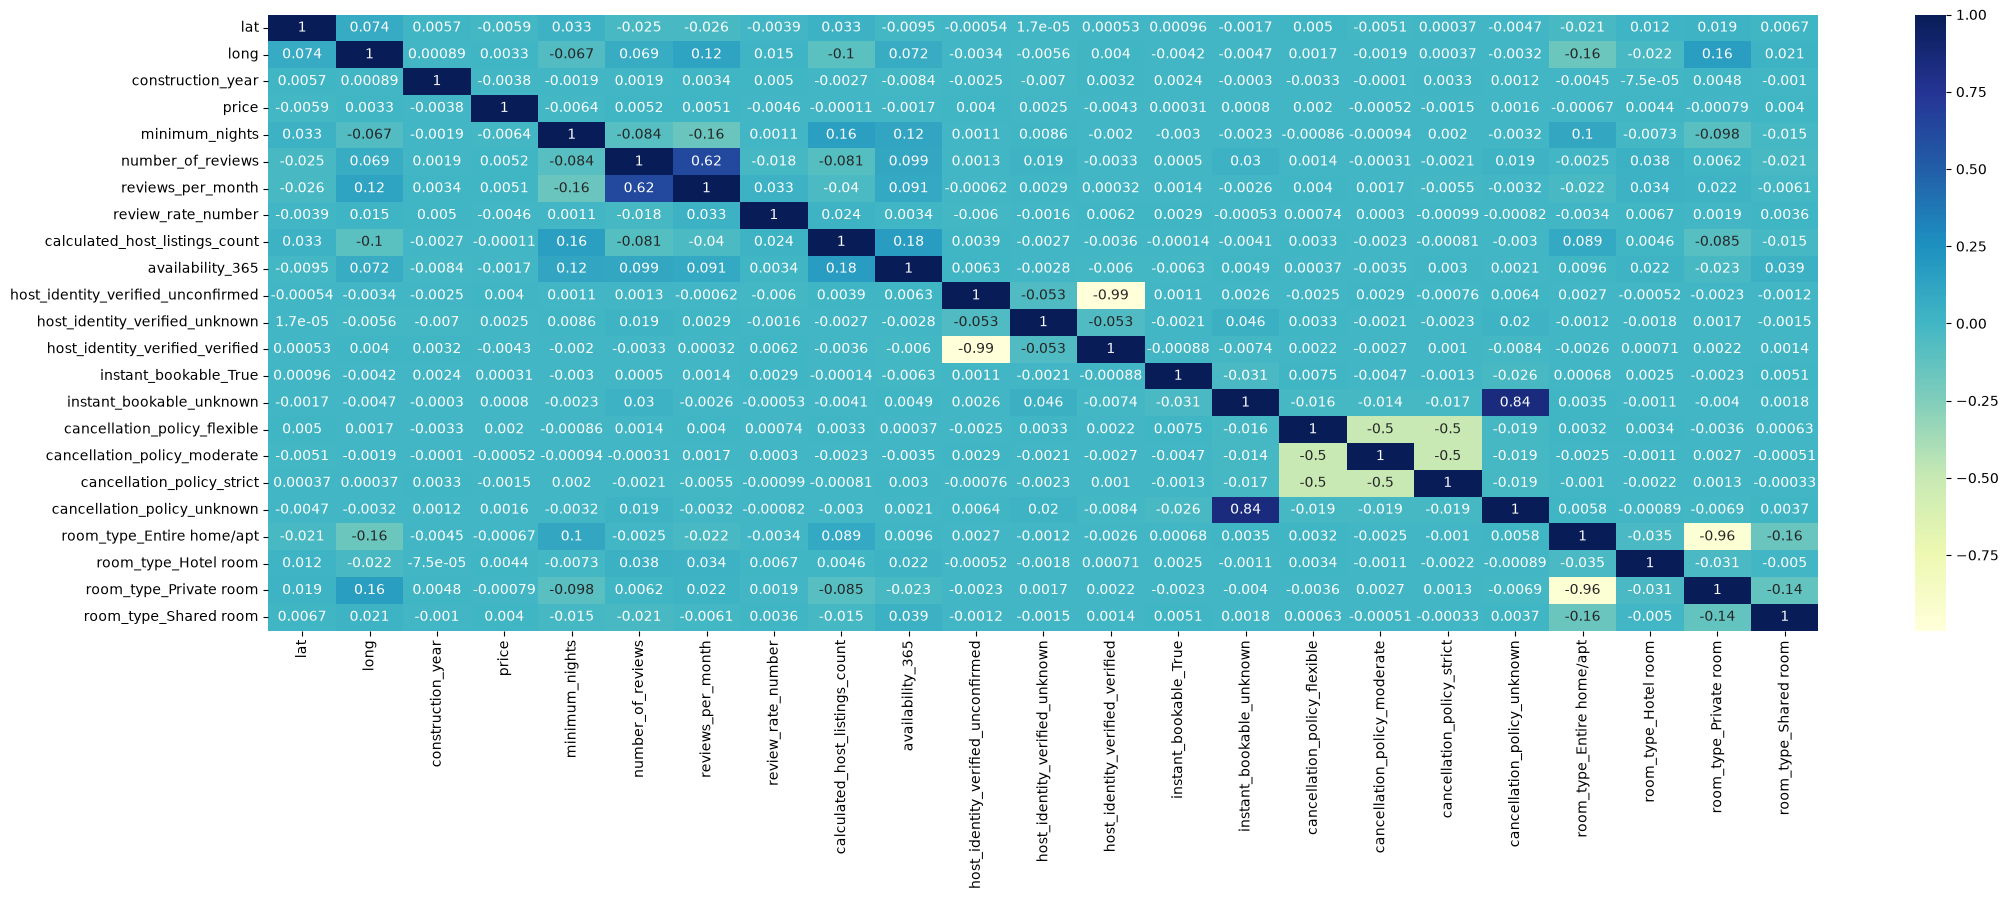

In [5]:
plt.figure(figsize=(25,8))
sns.heatmap(data.corr(),annot=True, cmap="YlGnBu" )

array([[<Axes: title={'center': 'lat'}>,
        <Axes: title={'center': 'long'}>,
        <Axes: title={'center': 'construction_year'}>],
       [<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>],
       [<Axes: title={'center': 'reviews_per_month'}>,
        <Axes: title={'center': 'review_rate_number'}>,
        <Axes: title={'center': 'calculated_host_listings_count'}>],
       [<Axes: title={'center': 'availability_365'}>, <Axes: >, <Axes: >]],
      dtype=object)

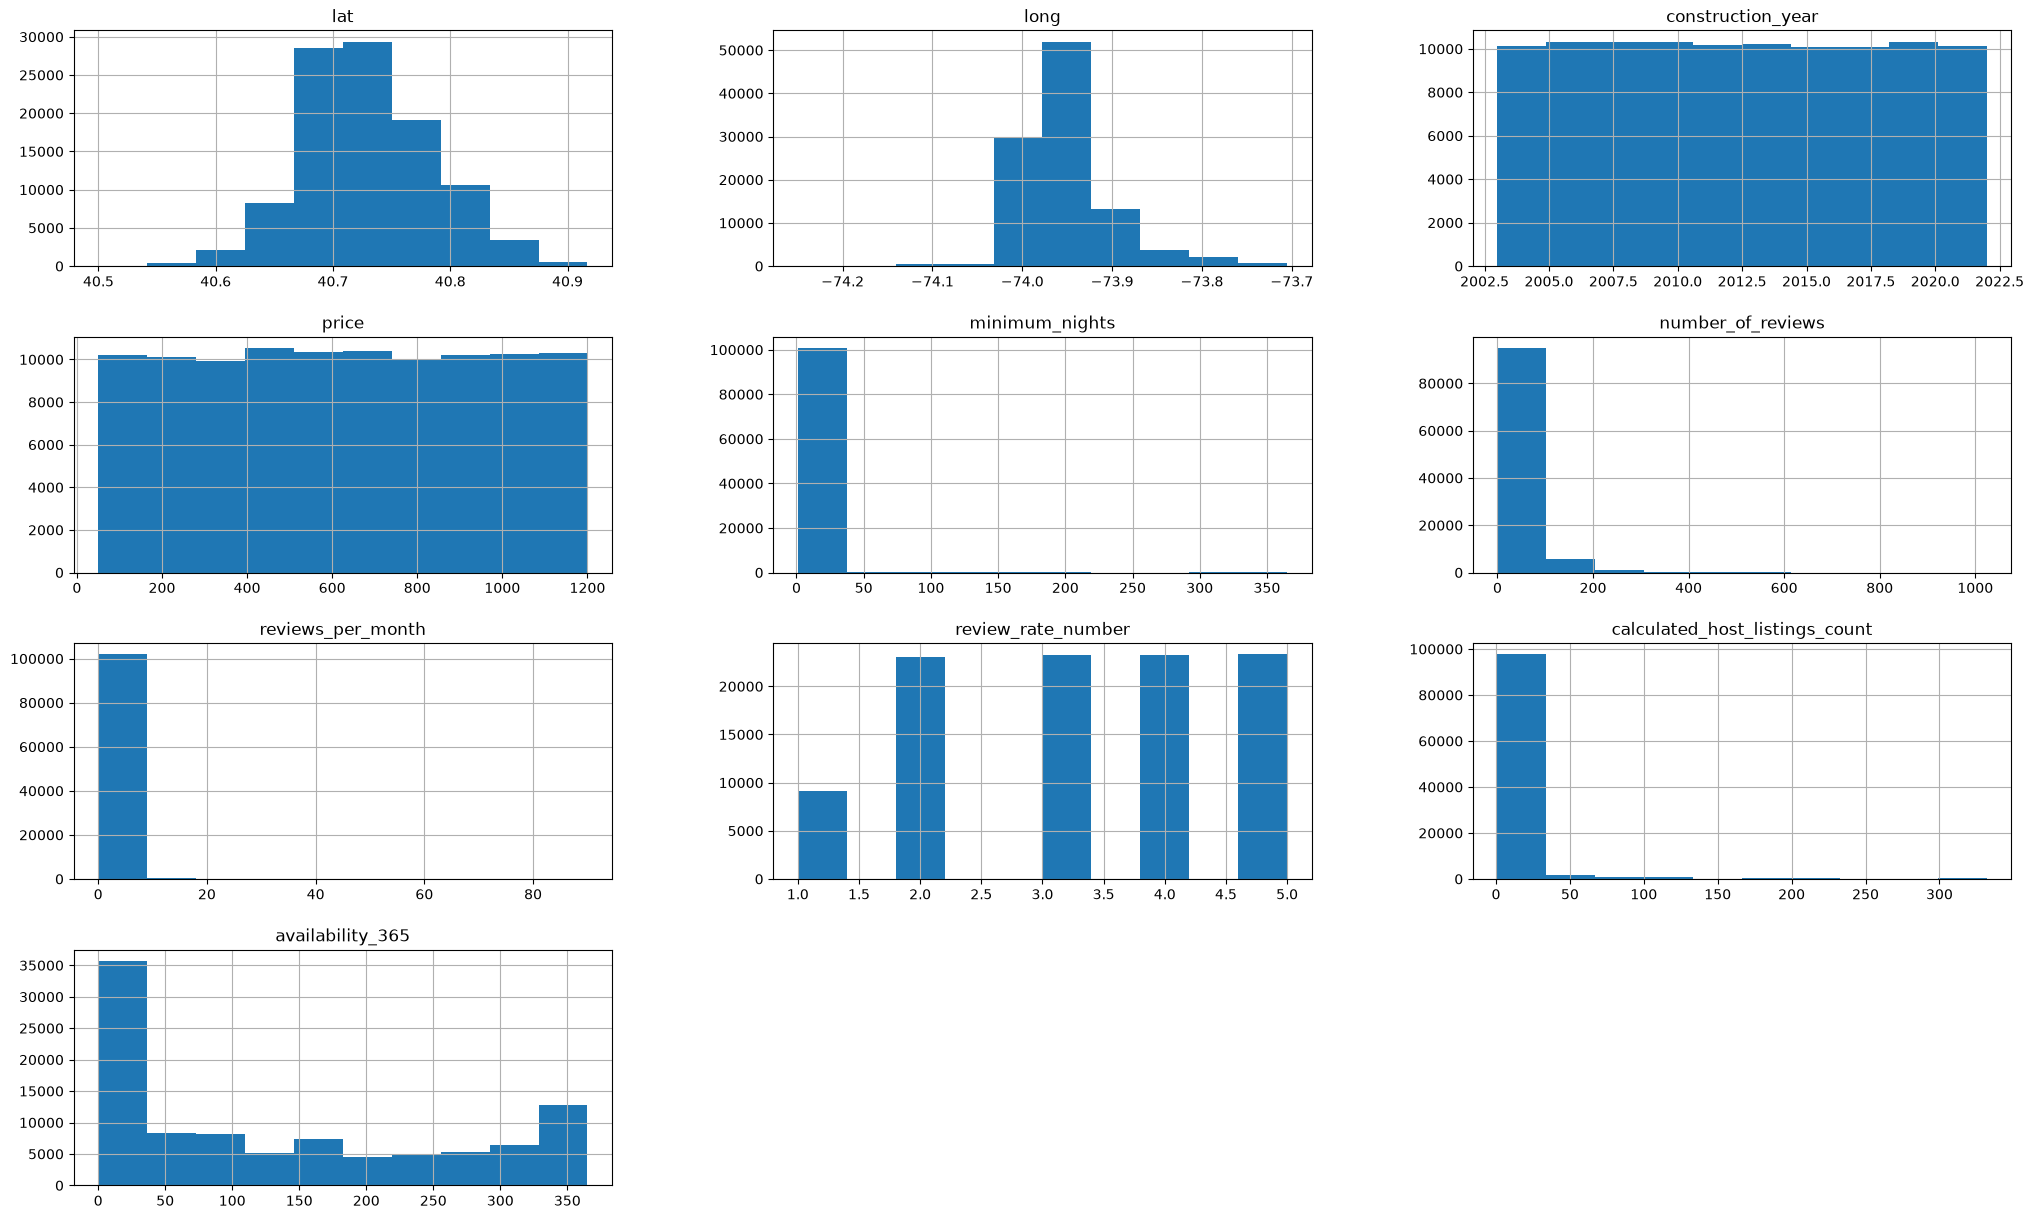

In [6]:
data.hist(figsize=(25,15))


In [7]:
data["minimum_nights"].min()
data["minimum_nights"].max()

data["availability_365"].min()
data["availability_365"].max()

data["minimum_nights"].describe()
(data["minimum_nights"] > 365).sum()

data["minimum_nights"] = np.log(data["minimum_nights"]) + 1
data["number_of_reviews"] = np.log1p(data["number_of_reviews"])
data["reviews_per_month"] = np.log1p(data["reviews_per_month"])
data["calculated_host_listings_count"] = np.log(data["calculated_host_listings_count"]) + 1



array([[<Axes: title={'center': 'lat'}>,
        <Axes: title={'center': 'long'}>,
        <Axes: title={'center': 'construction_year'}>],
       [<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>],
       [<Axes: title={'center': 'reviews_per_month'}>,
        <Axes: title={'center': 'review_rate_number'}>,
        <Axes: title={'center': 'calculated_host_listings_count'}>],
       [<Axes: title={'center': 'availability_365'}>, <Axes: >, <Axes: >]],
      dtype=object)

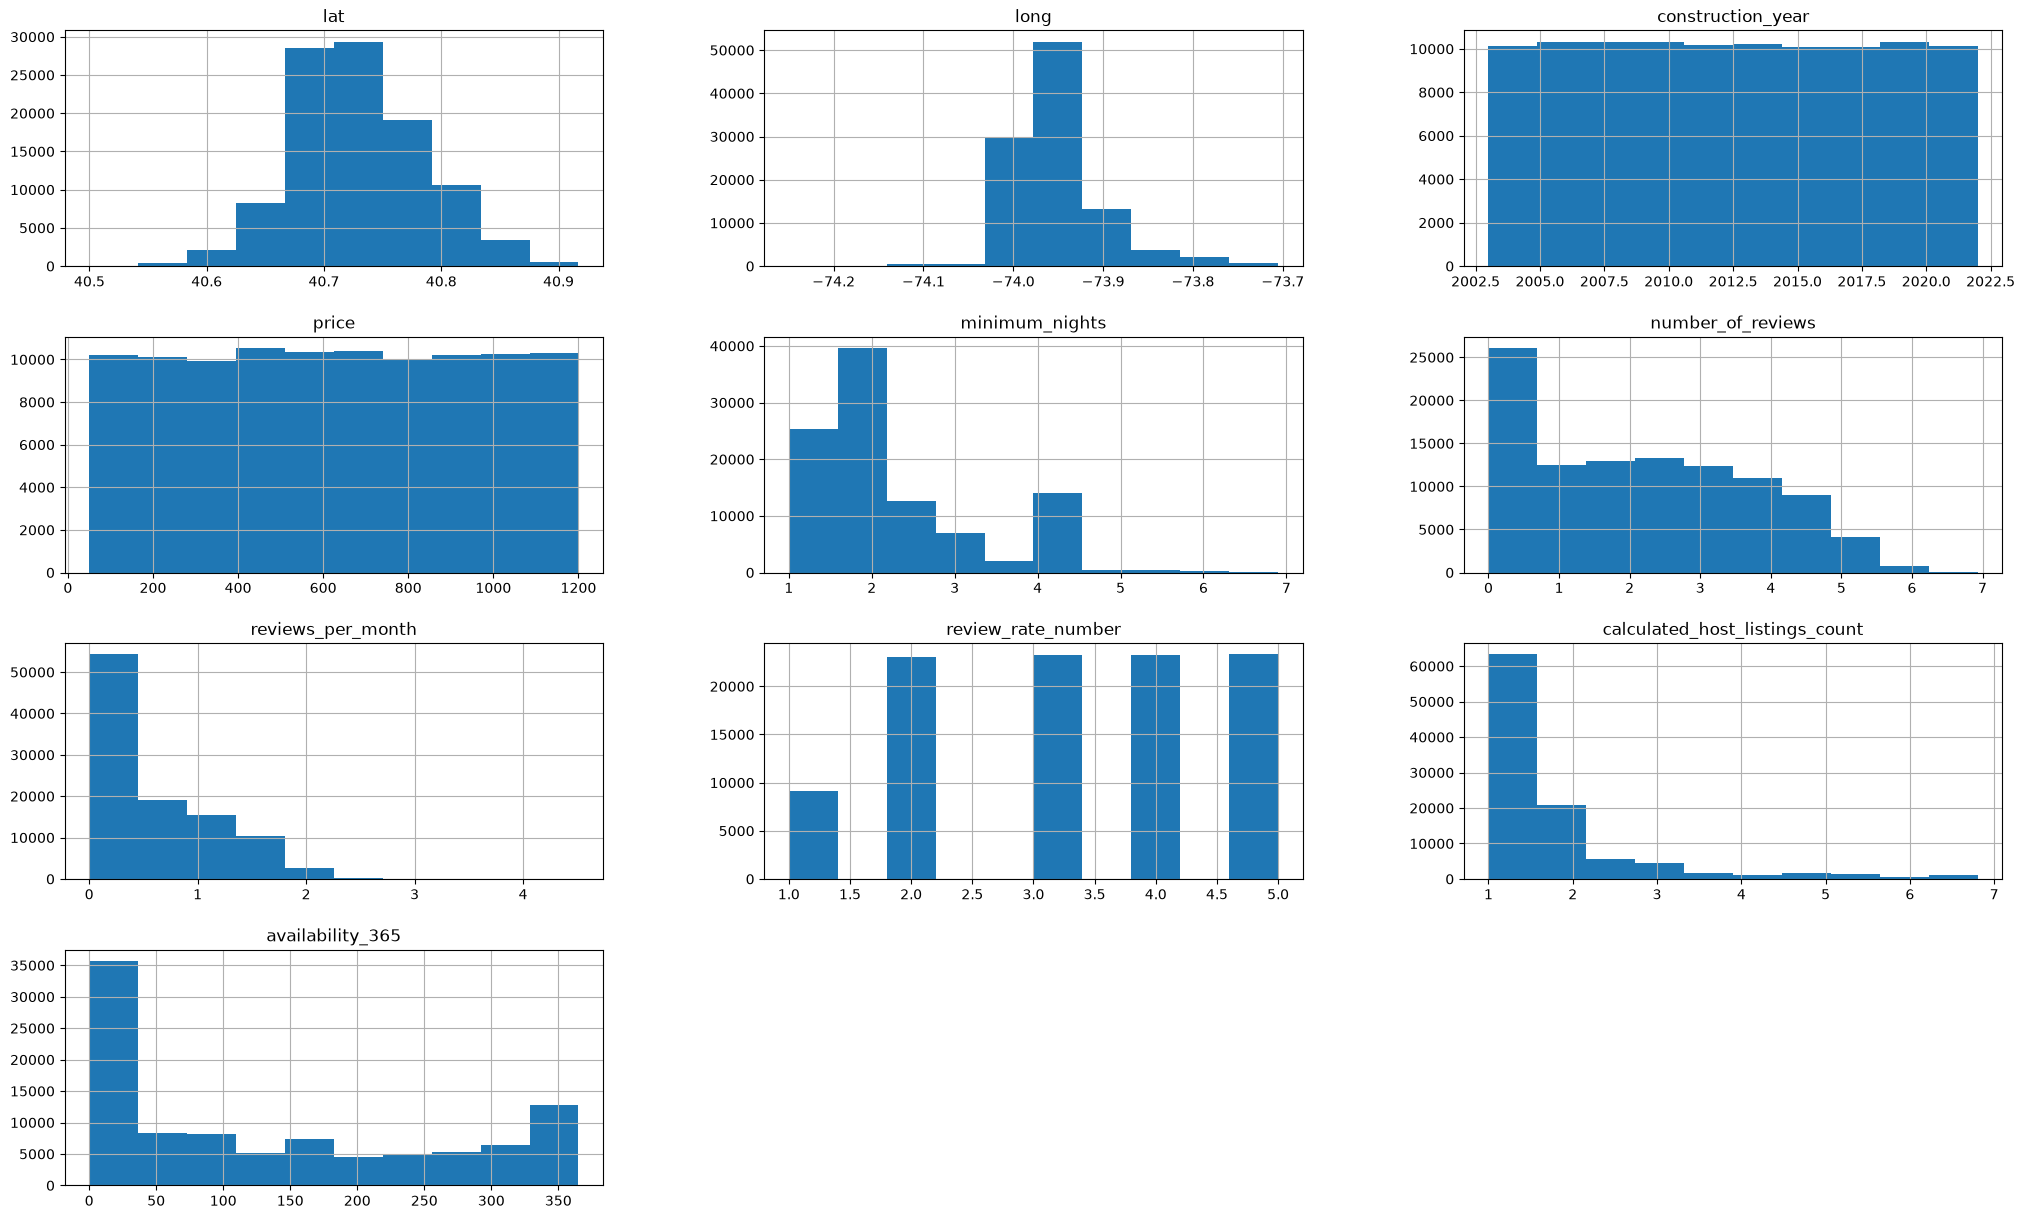

In [8]:
data.hist(figsize=(25,15))


In [9]:
data.describe()

,lat,long,construction_year,price,minimum_nights,number_of_reviews,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365
count,102344.00000,102344.000000,102142.000000,102352.000000,101895.000000,102169.000000,102208.000000,102026.000000,102033.000000,98702.000000
mean,40.72809,-73.949647,2012.487038,625.293536,2.224893,2.211222,0.583712,3.279282,1.632162,134.582754
std,0.05587,0.049522,5.765066,331.671614,1.140449,1.561736,0.570269,1.284458,1.129114,129.791401
min,40.49979,-74.249840,2003.000000,50.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,40.68873,-73.982570,2007.000000,340.000000,1.693147,0.693147,0.086178,2.000000,1.000000,2.000000
50%,40.72228,-73.954440,2012.000000,624.000000,2.098612,2.079442,0.392042,3.000000,1.000000,90.000000
75%,40.76276,-73.932350,2017.000000,913.000000,2.609438,3.433987,0.996949,4.000000,1.693147,254.000000
max,40.91697,-73.705220,2022.000000,1200.000000,6.899897,6.932448,4.510860,5.000000,6.805135,365.000000


<Axes: >

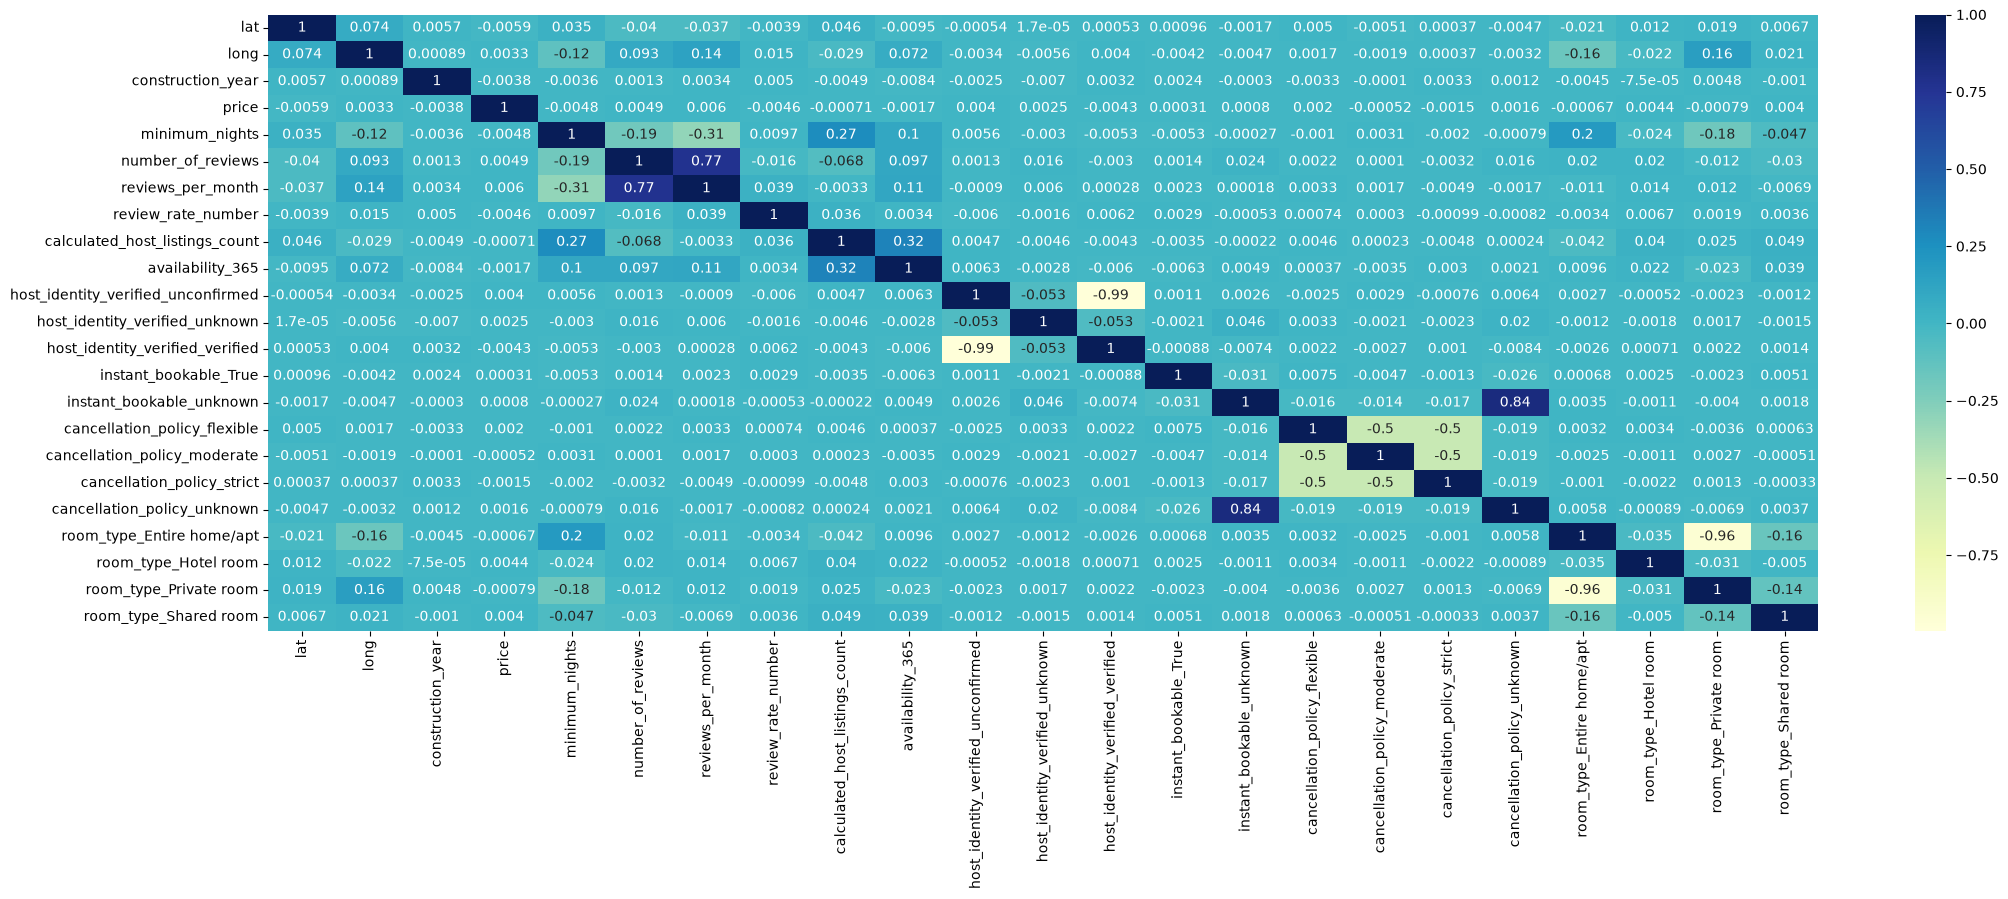

In [10]:
plt.figure(figsize=(25,8))
sns.heatmap(data.corr(),annot=True, cmap="YlGnBu" )

<Axes: xlabel='lat', ylabel='long'>

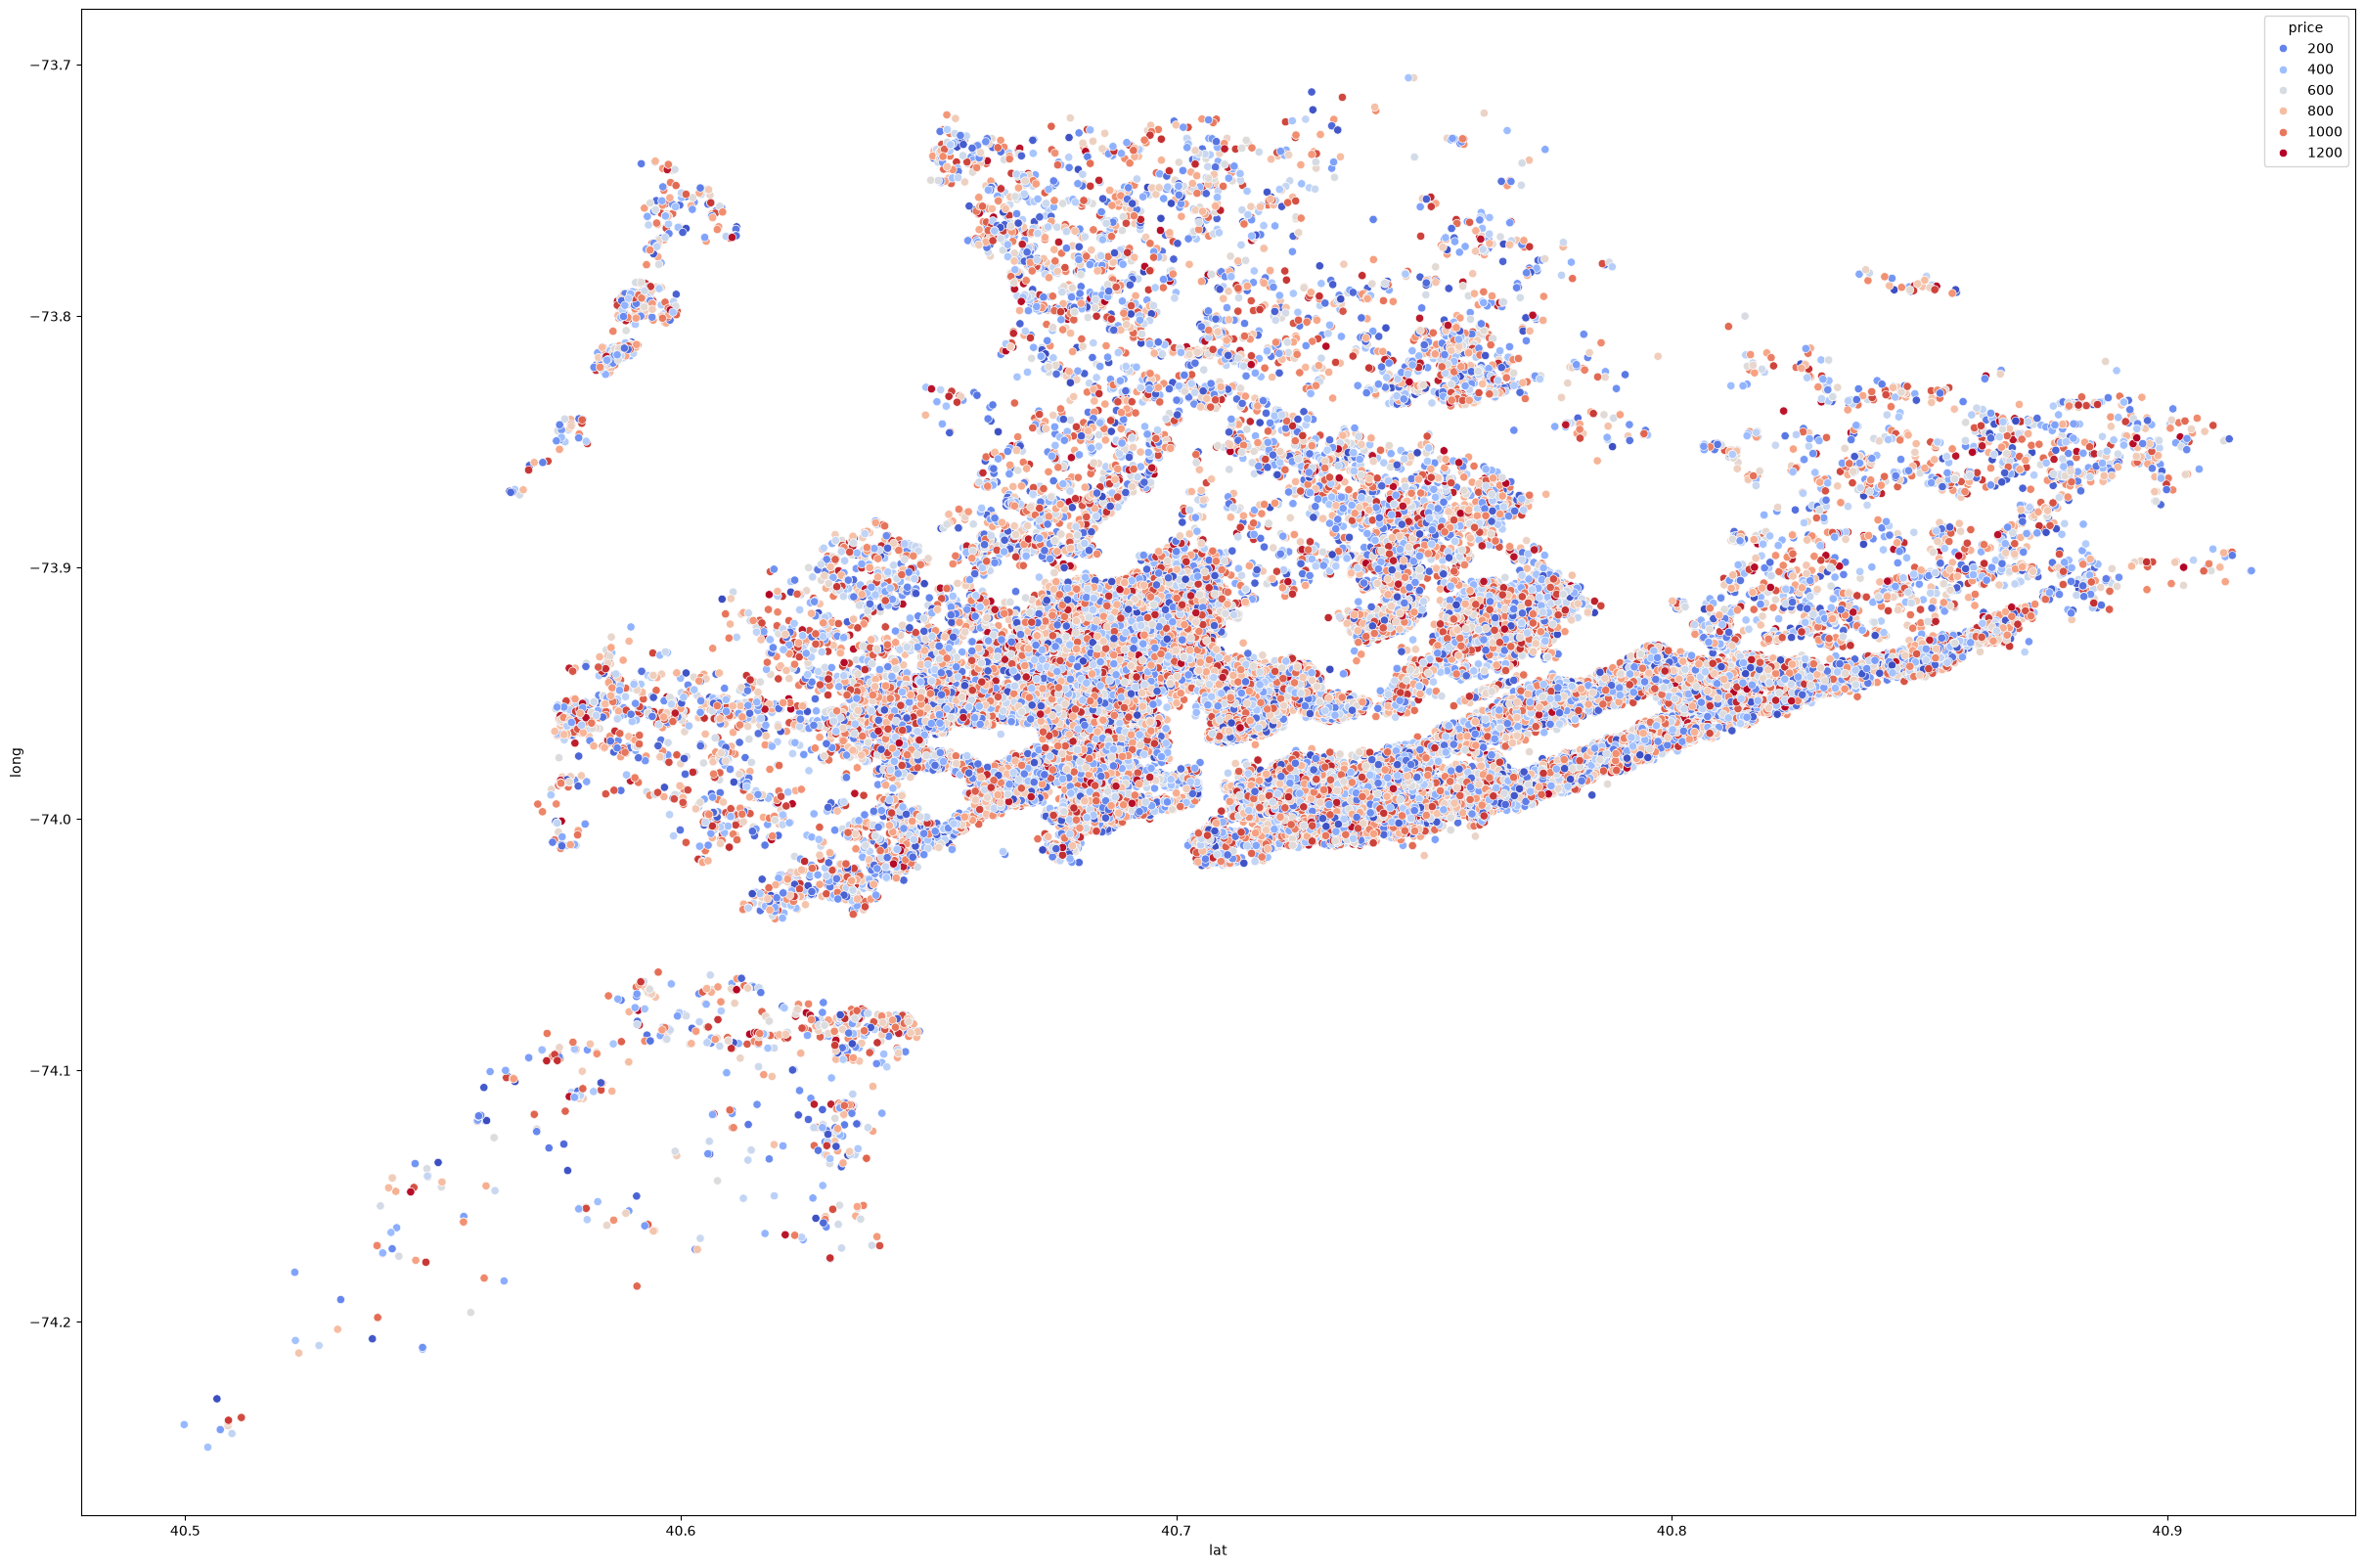

In [31]:
#map of the apartments
plt.figure(figsize=(30, 20))
sns.scatterplot(x="lat", y="long", data = data, hue="price", palette="coolwarm")

In [12]:
from sklearn.model_selection import train_test_split

X = data.drop(["price"], axis=1)
y = data["price"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [14]:
train_data = X_train.join(y_train)

## 2. Create a baseline model using all features.
    - Classification: Logistic Regression
    - Regression: Linear Regression

In [15]:
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline


# Let feature selectors pass missing values to the pipelines imputer
class ImputingPipeline(Pipeline):
    def __sklearn_tags__(self):
        tags = super().__sklearn_tags__()
        tags.input_tags.allow_nan = True
        return tags


bl_lin_reg = ImputingPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

bl_lin_reg.fit(X_train, y_train)

,steps,"[('imputer', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
feature_names_in_,"ndarray[object](22,)","['lat','long','construction_year',...,'room_type_Hotel room', 'room_type_Private room','room_type_Shared room']"
n_features_in_,int,22
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True


## 3. Evaluate baseline with your chosen metric (examples):
- Classification: accuracy, Recall, F1-score
- Regression: RMSE, MAE, R²

In [16]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred = bl_lin_reg.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))

score_mae_bl_lin_reg = mean_absolute_error(y_test, y_pred)

R2: -0.0006721515287615443
MAE: 285.53431590677235
RMSE: 330.3785554181183


## 4. Write 1–2 sentences: Why did you choose this metric for your problem?

I chose MAE because it expresses the average absolute prediction error in the same currency as the accommodation prices. It is easy to interpret and less sensitive to unusually large prediction errors than RMSE.

# Part B: Sequential Feature Selection


## B1. Sequential Forward Selection (SFS)

 ### B1/1.Run SBS to select the same k features.

In [17]:
from sklearn.feature_selection import SequentialFeatureSelector

k = round(0.25 * X_train.shape[1])

sfs = SequentialFeatureSelector(
    clone(bl_lin_reg),
    n_features_to_select=k,
    direction="forward",
    cv=5,
    scoring="neg_mean_absolute_error"
)
sfs.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,ImputingPipel...egression())])
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",6
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'neg_mean_absolute_error'
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",None
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](22,)","['lat','long','construction_year',...,'room_type_Hotel room', 'room_type_Private room','room_type_Shared room']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,22
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(6)


### B1/2. Report:
- Selected feature list
- CV score during selection
- Test-set score using only the selected features

In [18]:
sfs_selected_features = X_train.columns[sfs.get_support()]
print("Selected feature list :")
sfs_selected_features.tolist()

Selected feature list :


['lat',
 'construction_year',
 'minimum_nights',
 'review_rate_number',
 'cancellation_policy_moderate',
 'room_type_Private room']

In [19]:
from sklearn.model_selection import cross_val_score

sfs_cv_scores = cross_val_score(
    clone(bl_lin_reg),
    X_train[sfs_selected_features],
    y_train,
    cv=5,
    scoring = "neg_mean_absolute_error"
)
sfs_sv_mae = -sfs_cv_scores.mean()
print("CV score during selection (MAE):", sfs_sv_mae)

print("SFS CV-MAE:", sfs_sv_mae)


CV score during selection (MAE): 287.1867282980619
SFS CV-MAE: 287.1867282980619


In [20]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

sfs_model = clone(bl_lin_reg)

sfs_model.fit(
    X_train[sfs_selected_features],
    y_train
)

sfs_y_pred = sfs_model.predict(X_test[sfs_selected_features])

sfs_test_mae = mean_absolute_error(y_test, sfs_y_pred)
print("SFS test-set MAE:", sfs_test_mae)

SFS test-set MAE: 285.51891598528107


SFS selected six features and achieved a test MAE of 285.582, almost identical to the baseline MAE of 285.561. It reduced the number of features without meaningfully changing predictive performance.

## B2. Sequential Backward Selection (SBS)

In [21]:

sbs = SequentialFeatureSelector(
    clone(bl_lin_reg),
    n_features_to_select= k,
    direction= "backward",
    cv=5,
    scoring="neg_mean_absolute_error"
         )
sbs.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,ImputingPipel...egression())])
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",6
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'backward'
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'neg_mean_absolute_error'
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",None
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](22,)","['lat','long','construction_year',...,'room_type_Hotel room', 'room_type_Private room','room_type_Shared room']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,22
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(6)


In [22]:
sbs_selected_features = X_train.columns[sbs.get_support()]
print("Selected feature list :")
sbs_selected_features.tolist()

Selected feature list :


['lat',
 'construction_year',
 'minimum_nights',
 'review_rate_number',
 'room_type_Private room',
 'room_type_Shared room']

In [23]:
from sklearn.model_selection import cross_val_score

sbs_cv_scores = cross_val_score(
    clone(bl_lin_reg),
    X_train[sbs_selected_features],
    y_train,
    cv=5,
    scoring = "neg_mean_absolute_error"
)
sbs_sv_mae = -sbs_cv_scores.mean()
print("CV score during selection (MAE):", sbs_sv_mae)

print("SBS CV-MAE:", sbs_sv_mae)


CV score during selection (MAE): 287.19055132614204
SBS CV-MAE: 287.19055132614204


In [24]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

sbs_model = clone(bl_lin_reg)

sbs_model.fit(
    X_train[sbs_selected_features],
    y_train
)

sbs_y_pred = sbs_model.predict(X_test[sbs_selected_features])

sbs_test_mae = mean_absolute_error(y_test, sbs_y_pred)
print("SBS test-set MAE:", sbs_test_mae)

SBS test-set MAE: 285.507587108073


SBS shared four of its six selected features with SFS and achieved almost identical CV and test MAE values. Different subsets can arise because SFS greedily adds features from an empty set, while SBS removes features from the full set, making their choices depend on different intermediate subsets.

In [25]:
from mlxtend.feature_selection import SequentialFeatureSelector as FloatingSFS

bidir = FloatingSFS(
    clone(bl_lin_reg),
    k_features=k,
    forward=True,
    floating=True,
    scoring="neg_mean_absolute_error",
    cv=5
)

bidir.fit(X_train, y_train)

bidir_selected_features = list(bidir.k_feature_names_)
bidir_cv_mae = -bidir.k_score_

print("Selected features:", bidir_selected_features)
print("CV-MAE:", bidir_cv_mae)

Selected features: ['lat', 'construction_year', 'minimum_nights', 'review_rate_number', 'cancellation_policy_moderate', 'room_type_Private room']
CV-MAE: 287.1867282980619


In [26]:
bidir_model = clone(bl_lin_reg)
bidir_model.fit(X_train[bidir_selected_features], y_train)

bidir_y_pred = bidir_model.predict(X_test[bidir_selected_features])
bidir_test_mae = mean_absolute_error(y_test, bidir_y_pred)

print("Bidirectional test-set MAE:", bidir_test_mae)

Bidirectional test-set MAE: 285.51891598528107


Bidirectional selection can be preferable when a feature’s usefulness depends on which other features are included. Allowing both additions and removals lets it revise earlier decisions, potentially finding a better subset than pure forward or backward selection. It selection found the same six features as SFS and achieved the same test MAE, providing no additional improvement in this run.

# Part C: PCA as Dimensionality Reduction

## C1. Fit PCA (with scaling)

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regressor", LinearRegression())
])


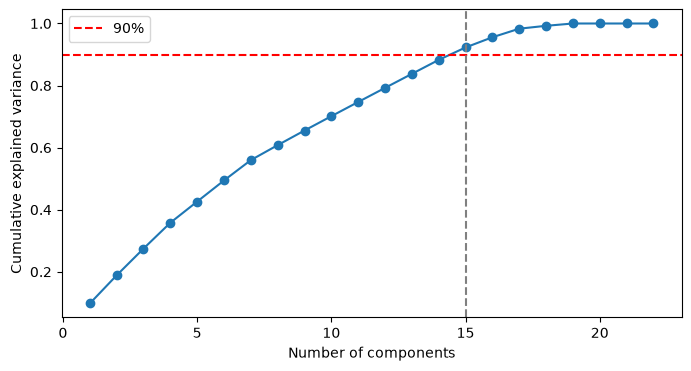

Selected number of components: 15


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['lat','long','construction_year',...,'room_type_Hotel room', 'room_type_Private room','room_type_Shared room']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_

In [28]:
pca_model[:-1].fit(X_train)

cumulative_variance = np.cumsum(
    pca_model.named_steps["pca"].explained_variance_ratio_
)

n_components = int(np.searchsorted(cumulative_variance, 0.90) + 1)

plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(0.90, color="red", linestyle="--", label="90%")
plt.axvline(n_components, color="gray", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.show()

print("Selected number of components:", n_components)

pca_model.set_params(pca__n_components=n_components)
pca_model.fit(X_train, y_train)

## C2. Evaluate PCA model

In [29]:
pca_cv_mae = -cross_val_score(
    clone(pca_model),
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
).mean()

pca_y_pred = pca_model.predict(X_test)
pca_test_mae = mean_absolute_error(y_test, pca_y_pred)

pca_step = pca_model.named_steps["pca"]

print("Components used:", pca_step.n_components_)
print(f"Explained variance: {pca_step.explained_variance_ratio_.sum():.2%}")
print("CV-MAE:", pca_cv_mae)
print("Test-set MAE:", pca_test_mae)


Components used: 15
Explained variance: 92.28%
CV-MAE: 287.2538413211622
Test-set MAE: 285.52242126434976


PCA can combine information from multiple correlated features into fewer components, reducing redundancy while retaining much of their variation. Its drawback is that the components are weighted combinations of original features, making them harder to interpret than directly selected columns. it retained 92.26% of the variance using 15 components, while achieving nearly the same test MAE as the baseline.

# Required Deliverables

In [30]:
comparison = pd.DataFrame([
    ["Baseline", X_train.shape[1], np.nan, score_mae_bl_lin_reg],
    ["SFS", len(sfs_selected_features), sfs_sv_mae, sfs_test_mae],
    ["SBS", len(sbs_selected_features), sbs_sv_mae, sbs_test_mae],
    ["Bidirectional", len(bidir_selected_features), bidir_cv_mae, bidir_test_mae],
    ["PCA", pca_step.n_components_, pca_cv_mae, pca_test_mae]
], columns=["Method", "Features / components", "CV-MAE", "Test-MAE"])

comparison.round(3)

,Method,Features / components,CV-MAE,Test-MAE
0,Baseline,22,NaN,285.534
1,SFS,6,287.187,285.519
2,SBS,6,287.191,285.508
3,Bidirectional,6,287.187,285.519
4,PCA,15,287.254,285.522


### FINAL SUMMARY:

I would recommend SFS because it uses only six original features while achieving almost the same test MAE as the baseline. These features are easier to interpret than PCA’s components. For this small target subset, forward selection requires fewer candidate evaluations than SBS and avoids the additional backward checks of bidirectional selection, suggesting a lower selection cost, although runtimes were not measured. This recommendation mainly reflects simplicity, since the methods showed no meaningful difference in predictive performance.
Future work could investigate richer predictors or nonlinear models, while alternative targets such as room type could be explored as separate prediction tasks.

In [32]:
output_path = Path("data/processed/Airbnb_Open_Data_added_features.csv")
data.to_csv(output_path, index=False)